In [1]:
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
import pytz
import re
import matplotlib.dates as mdates


In [2]:
# # populate total_scount

def calculate_total_scount(df):
    #print("calculate_total_scount")

    # Initialize the total_scount column with None or a default value
    if "total_scount" not in df.columns:
        df["total_scount"] = 0

    # Iterate over the rows
    for i in range(len(df)):
        current_ta = df.at[i, "wlan.ta_int"]
        current_scount = df.at[i, "wlan.qbss.scount"]

        # Look for a previous record where wlan.ta_int is one higher or lower
        j = i - 1  # Start with the immediately preceding row
        while j >= 0:
            prev_ta = df.at[j, "wlan.ta_int"]
            if abs(prev_ta - current_ta) == 1:
                # Found a previous record meeting the condition
                prev_scount = df.at[j, "wlan.qbss.scount"]
                df.at[i, "total_scount"] = current_scount + prev_scount
                break
            j -= 1  # Go to the next previous row

        # If no valid previous record was found, assign total_scount based on the next record's total_scount
        # this is broken
        if j < 0:
            k = i + 1  # Start with the next row
            while k < len(df):
                next_ta = df.at[k, "wlan.ta_int"]
                if next_ta == current_ta:
                    # Found the next record with the same wlan.ta_int
                    next_total_scount = df.at[k, "total_scount"]
                    df.at[i, "total_scount"] = next_total_scount
                    break
                k += 1
            
            # If no next record exists, keep total_scount as current_scount
            if k == len(df):
                df.at[i, "total_scount"] = current_scount

    # Copy the value of total_scount from the second record to the first record, improves min values and graphs
    # this needs to be done more elegantly later in case beacons are missing
    # calculate_total_scount was edited to correctly reflect first few rows
    #df.loc[0, "total_scount"] = df.loc[1, "total_scount"]
    #df.loc[2, "total_scount"] = df.loc[3, "total_scount"]
    
    # Ensure total_scount is of type integer
    df["total_scount"] = df["total_scount"].astype(int)

    return df

In [3]:
#  Define the function to generate the plot
#inputs are dataframes filtered to the radio, and further filtered for each SSID
def plot_channel_stations(radio_df, eduroam_df, byu_wifi_df, AP_name, start_time, end_time):
    #print("plot_channel_stations")
    plt.figure(figsize=(14, 7))  # Example size: 12 inches wide, 6 inches tall
    # Add a horizontal line at value 70 with 20% opacity
    plt.axhline(y=70, color='red', linestyle='-', alpha=0.2, zorder=-1)

    # Access the first record and get the value of 'radio_number'
    plot_radio_number = radio_df.iloc[0]["radio_number"]
    
    # Plot wlan.qbss.cu normalized as percentages
    plt.plot(radio_df["aruba_erm.time"], (radio_df["wlan.qbss.cu"] / 255) * 100, label="Channel Utilization (%)")

    # Fill the area below the line
    plt.fill_between(radio_df["aruba_erm.time"], (radio_df["wlan.qbss.cu"] / 255) * 100)


    # Plot total_scount
    plt.plot(radio_df["aruba_erm.time"], radio_df["total_scount"], label="Total Station Count")

    # Plot total_scount for "eduroam"
    #plt.plot(eduroam_df["aruba_erm.time"], eduroam_df["wlan.qbss.scount"], label="eduroam Station Count")

    # Plot total_scount for "BYU-WiFi"
    #plt.plot(byu_wifi_df["aruba_erm.time"], byu_wifi_df["wlan.qbss.scount"], label="BYU-WiFi Station Count")

    
    
    # Plot total_adc
    #plt.plot(radio_df["aruba_erm.time"], radio_df["wlan.qbss.adc"] / 32767 * 100, label="ADC (%)")

    #plot adc% + cu
    #adc updates less frequently than cu, but seems to be well correlated
    #plt.plot(radio_df["aruba_erm.time"], 100 - ((radio_df["wlan.qbss.adc"] / 32767 * 100) + (radio_df["wlan.qbss.cu"] / 255 * 100)), label="ADC + CU")



    # Add labels and title
    plt.xlabel(f"{start_time}   to   {end_time}", fontsize=14)
    plt.ylabel("Values", fontsize=14)
    plt.title(f"{AP_name} Radio {plot_radio_number}", fontsize=16)

    # Set the y-axis limits from 0 to 100
    plt.ylim(0, 100)

    # Format x-axis to show only time (hour:minute)
    #showing GMT, this is broken
    # time_formatter = mdates.DateFormatter("%H:%M")  # Format: Hour:Minute
    # plt.gca().xaxis.set_major_formatter(time_formatter)

    # Rotate x-axis labels for better visibility
    #plt.xticks(rotation=45)

    # Add a legend
    plt.legend()

    # Display the plot
    plt.show()

In [4]:
# Function to perform the analysis for a given radio DataFrame
def analyze_radio_group(radio_df, radio_number):
    #print("analyze_radio_group")
    # Ensure the DataFrame is sorted by timestamp
    radio_df = radio_df.sort_values(by="aruba_erm.time").reset_index(drop=True)

    # Count the total number of data points
    total_data_points = len(radio_df)

    # Calculate the greatest value of wlan.qbss.cu
    greatest_cutil = ((radio_df["wlan.qbss.cu"].max() / 255) * 100)

    # Calculate the least value of wlan.qbss.cu
    least_cutil = ((radio_df["wlan.qbss.cu"].min() / 255) * 100)

    # Count the number of data points where wlan.qbss.cu is greater than 178
    greater_than_178_count = (radio_df["wlan.qbss.cu"] > 178).sum()

    # Calculate the percentage of data points where wlan.qbss.cu is greater than 178
    percentage_greater_than_178 = (greater_than_178_count / total_data_points) * 100

    # Median wlan.qbss.cu
    median_cutil = ((radio_df["wlan.qbss.cu"].median() / 255) * 100)

    # Calculate the greatest value of wlan.qbss.scount
    greatest_scount = radio_df["total_scount"].max()

    # Calculate the median value of wlan.qbss.scount
    median_scount = radio_df["total_scount"].median()

    # Calculate the least value of wlan.qbss.scount
    least_scount = radio_df["total_scount"].min()

    # Print the results
    print()
    print(f"--- Radio Number {radio_number} ---")
    print(f"Total beacons: {total_data_points}")
    print(f"Number of beacons with high channel utilization: {greater_than_178_count}")
    print(f"Percentage of beacons with high channel utilization: {percentage_greater_than_178:.2f}%")
    print(f"Highest channel utilization: {greatest_cutil:.2f}%")
    print(f"Median channel utilization: {median_cutil:.2f}%")
    print(f"Lowest channel utilization: {least_cutil:.2f}%")
    print(f"Highest station count: {greatest_scount:.0f}")
    print(f"Median station count: {median_scount:.0f}")
    print(f"Lowest station count: {least_scount:.0f}")

    # Create a boolean mask for wlan.qbss.cu > 178
    condition = radio_df["wlan.qbss.cu"] > 178

    # Assign group numbers for consecutive periods where condition is True
    radio_df["group"] = (condition != condition.shift()).cumsum() * condition

    # Filter groups where wlan.qbss.cu > 178
    valid_groups = radio_df[radio_df["group"] > 0]

    # Check if there are valid groups (i.e., groups where wlan.qbss.cu > 178)
    if valid_groups.empty:
        print(f"No records found where wlan.qbss.cu > 178 for radio_number {radio_number}.")
    else:
       # Find the start and end of each group
        group_details = valid_groups.groupby("group").agg(
            first_index=("aruba_erm.time", "idxmin"),
            last_index=("aruba_erm.time", "idxmax")
        )

        # Extract the first and last timestamps directly
        group_details["first_in_sequence_time"] = valid_groups.groupby("group")["aruba_erm.time"].min()
        group_details["end_time"] = valid_groups.groupby("group")["aruba_erm.time"].max()

        # Calculate the duration between the start and end times, and add 1 second 
        # Aruba updates beacons once per 10, which is also the rate that we have captured. 1.024 is the time the first beacon represents
        group_details["duration"] = (group_details["end_time"] - group_details["first_in_sequence_time"]).dt.total_seconds() + 1.024

        # Find the group with the longest duration
        longest_group = group_details["duration"].idxmax()
        longest_row = group_details.loc[longest_group]

        # Extract details of the longest duration
        longest_duration = longest_row["duration"]
        longest_start_time = longest_row["first_in_sequence_time"]
        longest_end_time = longest_row["end_time"]

        # Print results for the specific radio_number
        print(f"Longest consecutive duration of high channel use: {longest_duration:.2f} seconds")
        print(f"First beacon of sequence: {longest_start_time}")
        print(f"Last beacon of sequence: {longest_end_time}")

In [5]:
# Receives the information for each AP and class information
# Reads the file and processes the information for that time/AP
def graph(AP_name, start_time, end_time):
    #print("graph")
    # Your graph function implementation here

    print(f"AP name: {AP_name}")

    # Define the base directory for the files
    base_dir = "Data"
    file_name = AP_name + ".parquet"

    # Load the data for the AP file into a dataframe
    # this could be improved by loading the file once per AP instead of once per class
    df = pd.read_parquet(
        f"{base_dir}/{file_name}",
        engine="pyarrow",
    )

    # copy the AP df for manipulation
    filtered_df = df.copy()

    # time column
    filtered_df.reset_index(inplace=True) #reset index so that the timestamp is in a column instead

    # Fix timestamp consistency
    # Localize only if the timestamps are naive
    if filtered_df["aruba_erm.time"].dt.tz is None:
        filtered_df["aruba_erm.time"] = filtered_df["aruba_erm.time"].dt.tz_localize("UTC")

    # Convert to UTC-7 (this can always be done after localization)
    filtered_df["aruba_erm.time"] = filtered_df["aruba_erm.time"].dt.tz_convert("Etc/GMT+7")

    # Filter the DataFrame by the date/time range
    filtered_df = filtered_df[(filtered_df['aruba_erm.time'] >= start_time) & (filtered_df['aruba_erm.time'] <= end_time)]

    # Ensure the DataFrame is sorted by timestamp
    filtered_df = filtered_df.sort_values(by="aruba_erm.time").reset_index(drop=True)


    # Convert wlan.qbss.scount to integer, handling NaN values
    filtered_df["wlan.qbss.scount"] = filtered_df["wlan.qbss.scount"].fillna(0).astype(int)
    filtered_df["wlan.qbss.cu"] = filtered_df["wlan.qbss.cu"].fillna(0).astype(int)
    filtered_df["wlan.qbss.adc"] = filtered_df["wlan.qbss.adc"].fillna(0).astype(int)

    # create wlan.ta_int column
    # Function to convert hex MAC address string to integer
    def mac_to_int(mac):
        return int(mac.replace(":", ""), 16)

    # Apply the conversion to the wlan.ta column
    filtered_df["wlan.ta_int"] = filtered_df["wlan.ta"].apply(mac_to_int)
    

    # Apply the function to calculate total_scount
    filtered_df = calculate_total_scount(filtered_df)

    # Verify the result
    #print(filtered_df[["wlan.ta_int", "wlan.qbss.scount", "total_scount"]].head())
    #print(filtered_df.dtypes)
    

    # Check Radio and SSID count
    # Verify all values in wlan.vs.aruba.ap_name are the same
    if filtered_df["wlan.vs.aruba.ap_name"].nunique() == 1:
        wlan_ap_name_value = filtered_df["wlan.vs.aruba.ap_name"].iloc[0]
        #print(f"Data from {wlan_ap_name_value}")
    else:
        raise ValueError("Values in wlan.vs.aruba.ap_name are not all the same.")

    # Count unique transmit addresses and corresponding SSIDs
    # ensures that data is clean and shows multi-radio APs
    # Group by wlan.ta and collect the corresponding wlan.ssid values
    bssid_info = (
        filtered_df.groupby("wlan.ta")["wlan.ssid"]
        .unique()  # Get unique SSIDs for each wlan.ta
        .reset_index()
        .rename(columns={"wlan.ta": "transmit_address", "wlan.ssid": "SSIDs"})
    )

    # Count the number of unique BSSIDs
    unique_bssid_count = bssid_info["transmit_address"].nunique()


    # add a column for unique radio number
    # Create the 'radio_number' column
    filtered_df = filtered_df.sort_values("wlan.ta_int").reset_index(drop=True)

    # Initialize the 'radio_number' column
    radio_number = 1
    radio_numbers = [radio_number]

    # Assign radio numbers based on 'wlan.ta_int'
    for i in range(1, len(filtered_df)):
        # Check if the difference between consecutive wlan.ta_int values is greater than 1
        if abs(filtered_df.loc[i, "wlan.ta_int"] - filtered_df.loc[i - 1, "wlan.ta_int"]) > 1:
            radio_number += 1  # Increment radio number if the condition is met
        radio_numbers.append(radio_number)

    # Add the radio_number column to the DataFrame
    filtered_df["radio_number"] = radio_numbers

    # Ensure the DataFrame is sorted by timestamp
    filtered_df = filtered_df.sort_values(by="aruba_erm.time").reset_index(drop=True)

    # Display the updated DataFrame
    #print(filtered_df.head())

    #print number of radios
    print(f"Number or 5GHz radios: {filtered_df['radio_number'].max()}")

    # Output the BSSID results
    print(f"Number of BSSIDs: {unique_bssid_count}")
    print("List of addresses and their corresponding SSIDs:")
    print(bssid_info)


    # Filter the DataFrame for records where radio_number is 1
    filtered_radio_1_df = filtered_df[filtered_df["radio_number"] == 1]
    # Filter the data for "eduroam" and "BYU-WiFi" SSIDs
    eduroam_radio_1_df = filtered_df[(filtered_df["wlan.ssid"] == "eduroam") & (filtered_df["radio_number"] == 1)]
    byu_wifi_radio_1_df = filtered_df[(filtered_df["wlan.ssid"] == "BYU-WiFi") & (filtered_df["radio_number"] == 1)]

    #  Filter the DataFrame for records where radio_number is 2
    filtered_radio_2_df = filtered_df[filtered_df["radio_number"] == 2]

    # Run the analysis for radio_number 1 (using filtered_radio_1_df)
    if not filtered_radio_1_df.empty:
        analyze_radio_group(filtered_radio_1_df, 1)
        # Plot for the first radio
        plot_channel_stations(filtered_radio_1_df, eduroam_radio_1_df, byu_wifi_radio_1_df, AP_name, start_time, end_time)

    # Run the analysis for radio_number 2 (using filtered_radio_2_df) only if it's not empty
    if not filtered_radio_2_df.empty:
        analyze_radio_group(filtered_radio_2_df, 2)
        # Filter the data for "eduroam" and "BYU-WiFi" SSIDs
        eduroam_radio_2_df = filtered_df[(filtered_df["wlan.ssid"] == "eduroam") & (filtered_df["radio_number"] == 2)]
        byu_wifi_radio_2_df = filtered_df[(filtered_df["wlan.ssid"] == "BYU-WiFi") & (filtered_df["radio_number"] == 2)]
        # Plot for the second radio
        plot_channel_stations(filtered_radio_2_df, eduroam_radio_2_df, byu_wifi_radio_2_df, AP_name, start_time, end_time)
    else:
        print(f"{AP_name} has only one 5GHz radio")

    #print()



In [10]:
#read in sample files
# this can be done after pickle files have been created from samples.py
sample_classes_df = pd.read_pickle('sample_classes.pkl')
sample_aps_df = pd.read_pickle('sample_aps.pkl')
sample_classrooms_df = pd.read_pickle('sample_classrooms.pkl')

In [11]:
print(sample_classes_df.head())


    location    course                start_time                  end_time  \
0     EB-404    CE 529 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   
1  JFSB-B042  PHIL 110 2024-11-04 08:00:00-07:00 2024-11-04 09:15:00-07:00   
2  JFSB-B160   ASL 101 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   
3   JKB-1005  WRTG 313 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   
4   JKB-1006  SPAN 321 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   

   enrolled  capacity  
0        14        69  
1        31        44  
2        17        45  
3        23        30  
4        28        42  


In [12]:

print(sample_aps_df.head())


                 Hostname Building  Room  Number Building-Room  Model Group  \
0  P-BNSN-W003-AP-01-W131     BNSN  W003       1     BNSN-W003    515     A   
1    P-BRMB-380-AP-01-265     BRMB   380       1      BRMB-380    515     A   
2      P-CB-369-AP-01-322       CB   369       1        CB-369    515     A   
3      P-CB-392-AP-01-322       CB   392       1        CB-392    515     A   
4     P-CTB-385-AP-01-535      CTB   385       1       CTB-385    515     A   

  Notes  
0   NaN  
1   NaN  
2   NaN  
3   NaN  
4   NaN  


In [13]:
print(sample_classrooms_df)

     Location Building  Room  Capacity Group   Schedule  ap_count
0   BNSN-W003     BNSN  W003        25     A  BNSN-W003         1
1    BRMB-380     BRMB   380        48     A   BRMB-380         1
2      CB-369       CB   369        40     A     CB-369         1
3      CB-392       CB   392        43     A     CB-392         1
4     CTB-385      CTB   385        30     A    CTB-385         1
5      EB-404       EB   404        69     B     EB-404         1
6    ESC-C261      ESC  C261        48     A   ESC-C261         1
7    ESC-C396      ESC  C396        24     A   ESC-C396         1
8   HBLL-3710     HBLL  3710        57     B  HBLL-3710         1
9    HRCB-116     HRCB   116        30     A   HRCB-116         1
10  JFSB-B042     JFSB  B042        44     A  JFSB-B042         1
11  JFSB-B160     JFSB  B160        45     A  JFSB-B160         1
12  JFSB-B164     JFSB  B164        48     A  JFSB-B164         1
13   JKB-1005      JKB  1005        30     A   JKB-1005         1
14   JKB-1

In [ ]:
# run analysis for only one location
# Specify the target location
target_location = "CTB-385"

# Loop through each row in sample_classes_df
for index, class_row in sample_classes_df.iterrows():
    location = class_row['location']
    
    # Skip rows that don't match the target location
    if location != target_location:
        continue
    
    start_time = class_row['start_time']
    end_time = class_row['end_time']
    course = class_row['course']
    enrolled = class_row['enrolled']
    capacity = class_row['capacity']
    ap_count = sample_classrooms_df.loc[sample_classrooms_df['Location'] == location, 'ap_count'].iloc[0]


    print("\n")
    print(f"Subject: {course}")
    print(f"Location: {location}")
    print(f"Start Time: {start_time}")
    print(f"End Time: {end_time}")
    print(f"Capacity: {capacity}")
    print(f"Enrolled: {enrolled}")
    print(f"Number of APs: {ap_count}")
    print()
    
    # Sub loop for each matching AP in sample_aps_df
    for ap_index, ap_row in sample_aps_df.iterrows():
        building_room = ap_row['Building-Room']
        
        # Check if the building-room matches the location
        if building_room == location:
            AP_name = ap_row['Hostname']
            
            
            # Call the graph function with the variables
            graph(AP_name, start_time, end_time)


In [ ]:
# loop for each class row, iterate through each AP at that location
# this will go through ALL data and take a while
# graph function at top


# Clean up column names for consistency (strip spaces)
sample_classes_df.columns = sample_classes_df.columns.str.strip()
sample_aps_df.columns = sample_aps_df.columns.str.strip()

# Loop through each row in sample_classes_df
for index, class_row in sample_classes_df.iterrows():
    location = class_row['location']
    start_time = class_row['start_time']
    end_time = class_row['end_time']
    course = class_row['course']
    enrolled = class_row['enrolled']
    capacity = class_row['capacity']
    ap_count = sample_classrooms_df.loc[sample_classrooms_df['Location'] == location, 'ap_count'].iloc[0]


    print("\n")
    print(f"Subject: {course}")
    print(f"Location: {location}")
    print(f"Start Time: {start_time}")
    print(f"End Time: {end_time}")
    print(f"Capacity: {capacity}")
    print(f"Enrolled: {enrolled}")
    print(f"AP count {ap_count}")
    print()
    
    # Sub loop for each matching AP in sample_aps_df
    for ap_index, ap_row in sample_aps_df.iterrows():
        building_room = ap_row['Building-Room']
        
        # Check if the building-room matches the location
        if building_room == location:
            AP_name = ap_row['Hostname']
            
            # Call the graph function with the variables
            graph(AP_name, start_time, end_time)


In [42]:
#moved to samples
# #Import sample files
sample_aps_df = pd.read_csv("/Users/yanzzee/Library/CloudStorage/Box-Box/DH-Personal/School/Research/Project/Code/Sample_APs.csv")
sample_classrooms_df = pd.read_csv("/Users/yanzzee/Library/CloudStorage/Box-Box/DH-Personal/School/Research/Project/Code/Sample_classrooms.csv")
sample_schedule_df = pd.read_csv("/Users/yanzzee/Library/CloudStorage/Box-Box/DH-Personal/School/Research/Project/Code/Sample_schedule.csv")






In [43]:
#moved to samples
# #build sample_df with each class period for the 2 weeks as a record
# Create an empty DataFrame with specified columns and data types
sample_classes_df = pd.DataFrame({
    "location": pd.Series(dtype="string"),
    "course": pd.Series(dtype="string"),
    "start_time": pd.Series(dtype="datetime64[us, Etc/GMT+7]"),
    "end_time": pd.Series(dtype="datetime64[us, Etc/GMT+7]"),
    "enrolled": pd.Series(dtype="int"),
    "capacity": pd.Series(dtype="int")
})

In [44]:
#moved to samples
# # Strip extra spaces from column names
sample_schedule_df.columns = sample_schedule_df.columns.str.strip()

# Verify the cleaned column names
#print(sample_schedule_df.columns)
#print(sample_classes_df.dtypes)


In [45]:
#moved to samples
# # Change the data types of the columns
sample_schedule_df = sample_schedule_df.astype({
    'Location': 'string',
    'Course': 'string',
    'Sec': 'string',
    'LQ': 'string',
    'H': 'string',
    'S': 'string',
    'Cr Hr': 'string',
    'Sec Type': 'string',
    'Class Period': 'string',
    'Days': 'string',
    'Instructor': 'string',
    'Status': 'string',
    'Assign To': 'string',
    'Begin Date': 'string',
    'End Date': 'string',
    'sample': 'string',
    'Size': 'int',   # Change 'Size' to integer
    'Enrl': 'int'    # Change 'Enrl' to integer
})

# Check the updated data types
#print(sample_schedule_df.dtypes)

In [46]:
#print(sample_aps_df.dtypes)
print(sample_classrooms_df.dtypes)
#print(sample_schedule_df.dtypes)

Location    object
Building    object
Room        object
Capacity     int64
Group       object
Schedule    object
dtype: object


In [47]:
sample_classrooms_df.head()

,Location,Building,Room,Capacity,Group,Schedule
0,BNSN-W003,BNSN,W003,25,A,BNSN-W003
1,BRMB-380,BRMB,380,48,A,BRMB-380
2,CB-369,CB,369,40,A,CB-369
3,CB-392,CB,392,43,A,CB-392
4,CTB-385,CTB,385,30,A,CTB-385


In [48]:
print(sample_schedule_df.head())

    Location        Course    Sec   LQ    H   S  Cr Hr Sec Type  \
0  BNSN-W003    CHEM 105     002         N        4.0             
1  BNSN-W003    NURS 296     009    L    N        0.0             
2  BNSN-W003    CHEM 105     004         N        4.0             
3  BNSN-W003    CHEM 101     003         N        3.0             
4  BNSN-W003   A HTG 100     043         N        3.0             

      Class Period   Days                Instructor  Size  Enrl Status  \
0   8:00a - 8:50a    TTh    Sorensen, Jason Joshua     25    21     C    
1   8:30a - 9:50a      M                                9     8     C    
2   9:00a - 9:50a    TTh    Sorensen, Jason Joshua     25    22     C    
3   9:00a - 9:50a      W        Watt, Richard Kent     25    26     C    
4   9:00a - 9:50a      F        Patterson, Kelly D     15     6     C    

                          Assign To Begin Date End Date     sample  
0   Chemistry and Biochemistry ***                       BNSN-W003  
1   Chemistry 

In [11]:
#don't use
# #import re
#not sure if this is needed

# Clean the 'Class Period' column in sample_schedule_df
sample_schedule_df['Class Period'] = sample_schedule_df['Class Period'].apply(
    lambda x: re.sub(r'[\xa0]+', ' ', str(x)).strip()  # Replace non-breaking spaces with regular spaces and remove extra spaces
)
sample_schedule_df['Class Period'] = sample_schedule_df['Class Period'].apply(
    lambda x: re.sub(r'[\x00-\x1F\x7F-\x9F]', '', x)  # Remove other non-printable characters
)

# Clean the 'Days' column in sample_schedule_df
sample_schedule_df['Days'] = sample_schedule_df['Days'].apply(
    lambda x: re.sub(r'[\xa0]+', ' ', str(x)).strip()  # Replace non-breaking spaces with regular spaces and remove extra spaces
)
sample_schedule_df['Days'] = sample_schedule_df['Days'].apply(
    lambda x: re.sub(r'[\x00-\x1F\x7F-\x9F]', '', x)  # Remove other non-printable characters
)

# Check the cleaned 'Class Period' column
print(sample_schedule_df['Location'].head())


0    BNSN-W003
1    BNSN-W003
2    BNSN-W003
3    BNSN-W003
4    BNSN-W003
Name: Location, dtype: string


In [49]:

#moved to samples
# # Define a function to clean a single cell
def clean_cell(value):
    # Ensure the value is a string, then clean it
    value = str(value)  # Convert to string if necessary
    value = re.sub(r'[\xa0]+', ' ', value)  # Replace non-breaking spaces with regular spaces
    value = re.sub(r'[\x00-\x1F\x7F-\x9F]', '', value)  # Remove non-printable characters
    return value.strip()  # Remove leading/trailing spaces

# Apply the cleaning function to every column in the DataFrame
sample_schedule_df = sample_schedule_df.apply(lambda col: col.map(clean_cell))

# Check the cleaned DataFrame
#print(sample_schedule_df.head())


In [50]:
#moved to samples
# verify clean data
# Access the first record of the DataFrame
first_record = sample_schedule_df.iloc[10]

# Print the first record, including hidden characters
for column, value in first_record.items():
    print(f"{column}: {repr(value)}")


Location: 'BNSN-W003'
Course: 'CHEM 106'
Sec: '016'
LQ: ''
H: 'N'
S: ''
Cr Hr: '3.0'
Sec Type: ''
Class Period: '12:00p - 12:50p'
Days: 'Th'
Instructor: 'Paxton, Walter F'
Size: '25'
Enrl: '22'
Status: 'C'
Assign To: 'Chemistry and Biochemistry ***'
Begin Date: ''
End Date: ''
sample: 'BNSN-W003'


In [19]:
#don't use
# # Create start_time and end_time columns from the Class Period column
sample_schedule_df[['start_time', 'end_time']] = sample_schedule_df['Class Period'].str.split(' - ', expand=True)

# Convert the new columns to strings (if they aren't already)
sample_schedule_df['start_time'] = sample_schedule_df['start_time'].astype(str)
sample_schedule_df['end_time'] = sample_schedule_df['end_time'].astype(str)

# Display the updated DataFrame to verify the new columns
print(sample_schedule_df[['Class Period', 'start_time', 'end_time']].head())


    Class Period start_time end_time
0  8:00a - 8:50a      8:00a    8:50a
1  8:30a - 9:50a      8:30a    9:50a
2  9:00a - 9:50a      9:00a    9:50a
3  9:00a - 9:50a      9:00a    9:50a
4  9:00a - 9:50a      9:00a    9:50a


In [35]:
#debug
# start_time_dt = datetime.strptime("8:00am", "%I:%M%p").time()
#print(start_time_dt)

08:00:00


In [51]:

#moved to samples
# # build the sample_classes_df
# Define the two-week schedule
# This is the sample dates
start_date = datetime(2024, 11, 4)
end_date = datetime(2024, 11, 18)
schedule_days = [start_date + timedelta(days=i) for i in range((end_date - start_date).days + 1)]

# Mapping of day abbreviations to Python weekday indices
day_mapping = {"M": 0, "T": 1, "W": 2, "Th": 3, "F": 4}

# Iterate through sample_schedule_df
for _, row in sample_schedule_df.iterrows():
    location = row["Location"]
    course = row["Course"]
    enrolled = int(row["Enrl"])
    class_period = row["Class Period"]
    days = row["Days"]

    # Split class_period into start and end times
    try:
        start_time_str, end_time_str = class_period.split(" - ")
        start_time_str += "m"
        end_time_str += "m"
        start_time_dt = datetime.strptime(start_time_str, "%I:%M%p").time()
        end_time_dt = datetime.strptime(end_time_str, "%I:%M%p").time()
    except ValueError:
        continue  # Skip if Class Period is malformed

    # Determine which days the class meets and create entries for each valid day
    if days:
        for day_abbreviation in day_mapping.keys():
            if day_abbreviation in days:
                day_index = day_mapping[day_abbreviation]

                for date in schedule_days:
                    if date.weekday() == day_index:
                        # Combine the date and time for start_time and end_time
                        start_datetime = datetime.combine(date, start_time_dt)
                        end_datetime = datetime.combine(date, end_time_dt)

                        # Add the entry to sample_classes_df
                        sample_classes_df = pd.concat(
                            [
                                sample_classes_df,
                                pd.DataFrame(
                                    {
                                        "location": [location],
                                        "course": [course],
                                        "start_time": [start_datetime],
                                        "end_time": [end_datetime],
                                        "enrolled": [enrolled],
                                        "capacity": [None],  # Capacity is not provided in sample_schedule_df
                                    }
                                ),
                            ],
                            ignore_index=True,
                        )

# Print the result
print(sample_classes_df.head())


    location    course           start_time             end_time  enrolled  \
0  BNSN-W003  CHEM 105  2024-11-05 08:00:00  2024-11-05 08:50:00        21   
1  BNSN-W003  CHEM 105  2024-11-12 08:00:00  2024-11-12 08:50:00        21   
2  BNSN-W003  CHEM 105  2024-11-07 08:00:00  2024-11-07 08:50:00        21   
3  BNSN-W003  CHEM 105  2024-11-14 08:00:00  2024-11-14 08:50:00        21   
4  BNSN-W003  NURS 296  2024-11-04 08:30:00  2024-11-04 09:50:00         8   

  capacity  
0     None  
1     None  
2     None  
3     None  
4     None  


In [52]:
#moved to samples
# #find room capacity values and add to sample_classes_df
# Ensure both DataFrames are stripped of any leading/trailing spaces in their column names
sample_classes_df.columns = sample_classes_df.columns.str.strip()
sample_classrooms_df.columns = sample_classrooms_df.columns.str.strip()

# Create a dictionary from the sample_classrooms_df for fast look-up of 'Capacity' based on 'Location'
location_capacity_dict = dict(zip(sample_classrooms_df['Location'], sample_classrooms_df['Capacity']))

# Iterate through the rows of sample_classes_df and update the 'capacity' column based on the 'Location'
for index, row in sample_classes_df.iterrows():
    location = row['location']  # Assuming 'location' column is lowercase in sample_classes_df
    if location in location_capacity_dict:
        sample_classes_df.at[index, 'capacity'] = location_capacity_dict[location]

# Now the 'capacity' column in sample_classes_df is filled with the corresponding values from sample_classrooms_df
print(sample_classes_df[['location', 'capacity']].head())



    location capacity
0  BNSN-W003       25
1  BNSN-W003       25
2  BNSN-W003       25
3  BNSN-W003       25
4  BNSN-W003       25


In [53]:
sample_classes_df.head()

,location,course,start_time,end_time,enrolled,capacity
0,BNSN-W003,CHEM 105,2024-11-05 08:00:00,2024-11-05 08:50:00,21,25
1,BNSN-W003,CHEM 105,2024-11-12 08:00:00,2024-11-12 08:50:00,21,25
2,BNSN-W003,CHEM 105,2024-11-07 08:00:00,2024-11-07 08:50:00,21,25
3,BNSN-W003,CHEM 105,2024-11-14 08:00:00,2024-11-14 08:50:00,21,25
4,BNSN-W003,NURS 296,2024-11-04 08:30:00,2024-11-04 09:50:00,8,25


In [54]:
print(sample_classes_df.dtypes)

location      object
course        object
start_time    object
end_time      object
enrolled       int64
capacity      object
dtype: object


In [55]:

#moved to samples
# # Ensure start_time and end_time are datetime objects
sample_classes_df['start_time'] = pd.to_datetime(sample_classes_df['start_time'], errors='coerce')
sample_classes_df['end_time'] = pd.to_datetime(sample_classes_df['end_time'], errors='coerce')
# Convert the start_time and end_time columns to 'Etc/GMT+7' timezone
sample_classes_df['start_time'] = sample_classes_df['start_time'].dt.tz_localize('Etc/GMT+7', ambiguous='NaT')
sample_classes_df['end_time'] = sample_classes_df['end_time'].dt.tz_localize('Etc/GMT+7', ambiguous='NaT')


In [56]:

#duplicate# Set the current timezone (assumed as UTC for example)
#sample_classes_df['start_time'] = sample_classes_df['start_time'].dt.tz_localize('UTC').dt.tz_convert('Etc/GMT+7')
#sample_classes_df['end_time'] = sample_classes_df['end_time'].dt.tz_localize('UTC').dt.tz_convert('Etc/GMT+7')
# Print the updated data types
print(sample_classes_df.dtypes)

location                         object
course                           object
start_time    datetime64[ns, Etc/GMT+7]
end_time      datetime64[ns, Etc/GMT+7]
enrolled                          int64
capacity                         object
dtype: object


In [57]:

#moved to samples
# #change datatypes
# Fill missing values in 'enrolled' and 'capacity' with 0
sample_classes_df['enrolled'] = sample_classes_df['enrolled'].fillna(0).astype(int)
sample_classes_df['capacity'] = sample_classes_df['capacity'].fillna(0).astype(int)

# Change the data types of other columns
sample_classes_df = sample_classes_df.astype({
    'location': 'string',
    'course': 'string'
})

# Print the updated data types to verify
print(sample_classes_df.dtypes)


location                 string[python]
course                   string[python]
start_time    datetime64[ns, Etc/GMT+7]
end_time      datetime64[ns, Etc/GMT+7]
enrolled                          int64
capacity                          int64
dtype: object


/var/folders/xv/0nk5b_690m9907q_1d0by4fr0000gq/T/ipykernel_4408/2203364963.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sample_classes_df['capacity'] = sample_classes_df['capacity'].fillna(0).astype(int)


In [58]:
sample_classes_df.head()

,location,course,start_time,end_time,enrolled,capacity
0,BNSN-W003,CHEM 105,2024-11-05 08:00:00-07:00,2024-11-05 08:50:00-07:00,21,25
1,BNSN-W003,CHEM 105,2024-11-12 08:00:00-07:00,2024-11-12 08:50:00-07:00,21,25
2,BNSN-W003,CHEM 105,2024-11-07 08:00:00-07:00,2024-11-07 08:50:00-07:00,21,25
3,BNSN-W003,CHEM 105,2024-11-14 08:00:00-07:00,2024-11-14 08:50:00-07:00,21,25
4,BNSN-W003,NURS 296,2024-11-04 08:30:00-07:00,2024-11-04 09:50:00-07:00,8,25


In [120]:
sample_classrooms_df.head()

,Location,Building,Room,Capacity,Group,Schedule,ap_count
0,BNSN-W003,BNSN,W003,25,A,BNSN-W003,1
1,BRMB-380,BRMB,380,48,A,BRMB-380,1
2,CB-369,CB,369,40,A,CB-369,1
3,CB-392,CB,392,43,A,CB-392,1
4,CTB-385,CTB,385,30,A,CTB-385,1


In [60]:
sample_aps_df.head()

,Hostname,Building,Room,Number,Building-Room,Model,Group,Notes
0,P-BNSN-W003-AP-01-W131,BNSN,W003,1,BNSN-W003,515,A,NaN
1,P-BRMB-380-AP-01-265,BRMB,380,1,BRMB-380,515,A,NaN
2,P-CB-369-AP-01-322,CB,369,1,CB-369,515,A,NaN
3,P-CB-392-AP-01-322,CB,392,1,CB-392,515,A,NaN
4,P-CTB-385-AP-01-535,CTB,385,1,CTB-385,515,A,NaN


In [106]:

#moved to samples
# # Clean up column names for consistency (strip spaces)
sample_classes_df.columns = sample_classes_df.columns.str.strip()
sample_aps_df.columns = sample_aps_df.columns.str.strip()

# sort by class time
sample_classes_df = sample_classes_df.sort_values(by=['start_time', 'location']).reset_index(drop=True)
print(sample_classes_df.head())


    location    course                start_time                  end_time  \
0     EB-404    CE 529 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   
1  JFSB-B042  PHIL 110 2024-11-04 08:00:00-07:00 2024-11-04 09:15:00-07:00   
2  JFSB-B160   ASL 101 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   
3   JKB-1005  WRTG 313 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   
4   JKB-1006  SPAN 321 2024-11-04 08:00:00-07:00 2024-11-04 08:50:00-07:00   

   enrolled  capacity  
0        14        69  
1        31        44  
2        17        45  
3        23        30  
4        28        42  


In [107]:
#moved to samples
# # write sample dataframes to files so they don't have to be cleaned again
sample_classrooms_df.to_pickle('/Users/yanzzee/Library/CloudStorage/Box-Box/DH-Personal/School/Research/Project/Code/sample_classrooms.pkl')
sample_aps_df.to_pickle('/Users/yanzzee/Library/CloudStorage/Box-Box/DH-Personal/School/Research/Project/Code/sample_aps.pkl')
sample_classes_df.to_pickle('/Users/yanzzee/Library/CloudStorage/Box-Box/DH-Personal/School/Research/Project/Code/sample_classes.pkl')

In [28]:
#moved to graph function
# variables for input, iteration
AP_name = "P-JKB-1006-AP-01-1017A"
# Define the base directory for the file
base_dir = "/Users/yanzzee/Library/CloudStorage/Box-Box/DH-Networking/Projects/Research/working_data"
file_name = AP_name + ".parquet"

# create separate df for location info
#location
#date
#start time
#end time
#subject
#room capacity
#enrolled count


# Define the date/time range - these need to go at the beginning
# Convert string timestamps to datetime objects
start_time = pd.to_datetime('2024-11-04 09:00:00')
end_time = pd.to_datetime('2024-11-04 09:50:00')

# Localize to UTC-7 (Etc/GMT+7)
start_time = start_time.tz_localize('Etc/GMT+7')
end_time = end_time.tz_localize('Etc/GMT+7')

# Now both start_time and end_time are in UTC-7
print(f"AP name: {AP_name}")
print(f"Start time: {start_time}")
print(f"End time: {end_time}")

AP name: P-JKB-1006-AP-01-1017A
Start time: 2024-11-04 09:00:00-07:00
End time: 2024-11-04 09:50:00-07:00


In [29]:
#moved to graph function
# Load the data
#need to make this a variable for input

df = pd.read_parquet(
    f"{base_dir}/{file_name}",
    engine="pyarrow",
)

In [30]:
print(file_name)

NameError: name 'file_name' is not defined

<Axes: xlabel='aruba_erm.time'>

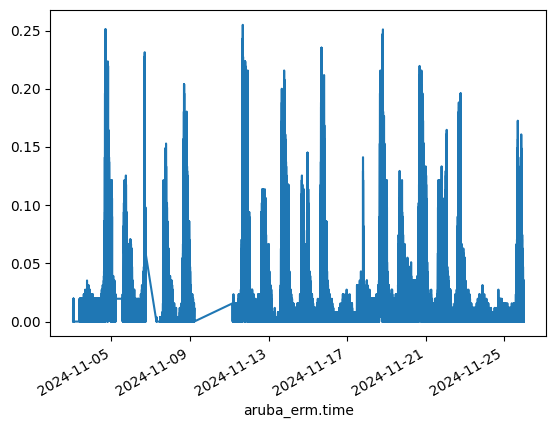

In [407]:
(df["wlan.qbss.cu"] / 255).plot()

In [215]:
print(df[['wlan.ta', 'wlan.vs.aruba.ap_name', 'wlan.ssid', 'wlan.qbss.scount', 
          'wlan.qbss.cu', 'wlan.qbss.adc']].head(10))

                                      wlan.ta   wlan.vs.aruba.ap_name  \
aruba_erm.time                                                          
2024-11-03 01:00:00.915736  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:00.915864  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:01.129552  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:01.129804  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:01.917959  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:01.918146  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:02.921191  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:02.921368  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:03.923850  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
2024-11-03 01:00:03.924007  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   

                           wlan.ssid  wlan.qbss.scount  wlan.qbss.cu  \
aruba_erm.time                                     

In [124]:
print(df.index)

DatetimeIndex(['2024-11-03 01:00:00.915736', '2024-11-03 01:00:00.915864',
               '2024-11-03 01:00:01.129552', '2024-11-03 01:00:01.129804',
               '2024-11-03 01:00:01.917959', '2024-11-03 01:00:01.918146',
               '2024-11-03 01:00:02.921191', '2024-11-03 01:00:02.921368',
               '2024-11-03 01:00:03.923850', '2024-11-03 01:00:03.924007',
               ...
               '2024-11-26 00:07:13.731032', '2024-11-26 00:07:13.731119',
               '2024-11-26 00:07:14.732699', '2024-11-26 00:07:14.732817',
               '2024-11-26 00:07:15.735130', '2024-11-26 00:07:15.735199',
               '2024-11-26 00:07:16.736866', '2024-11-26 00:07:16.736958',
               '2024-11-26 00:07:17.738605', '2024-11-26 00:07:17.738707'],
              dtype='datetime64[us]', name='aruba_erm.time', length=4141208, freq=None)


In [30]:
#moved to graph function
# copy the df for manipulation
filtered_df = df.copy()

In [168]:
print(filtered_df.head(10))

                                      wlan.ta wlan.vs.aruba.ap_name wlan.ssid  \
aruba_erm.time                                                                  
2024-11-03 01:00:00.140574  d0:4d:c6:df:a7:d1    P-EB-404-AP-01-419   eduroam   
2024-11-03 01:00:00.550216  d0:4d:c6:df:a7:e1    P-EB-404-AP-01-419   eduroam   
2024-11-03 01:00:00.959816  d0:4d:c6:df:a7:e0    P-EB-404-AP-01-419  BYU-WiFi   
2024-11-03 01:00:01.062176  d0:4d:c6:df:a7:d0    P-EB-404-AP-01-419  BYU-WiFi   
2024-11-03 01:00:01.164615  d0:4d:c6:df:a7:d1    P-EB-404-AP-01-419   eduroam   
2024-11-03 01:00:01.574438  d0:4d:c6:df:a7:e1    P-EB-404-AP-01-419   eduroam   
2024-11-03 01:00:01.983833  d0:4d:c6:df:a7:e0    P-EB-404-AP-01-419  BYU-WiFi   
2024-11-03 01:00:02.086226  d0:4d:c6:df:a7:d0    P-EB-404-AP-01-419  BYU-WiFi   
2024-11-03 01:00:02.188895  d0:4d:c6:df:a7:d1    P-EB-404-AP-01-419   eduroam   
2024-11-03 01:00:02.598293  d0:4d:c6:df:a7:e1    P-EB-404-AP-01-419   eduroam   

                           

In [219]:
print(filtered_df.head(10))

              aruba_erm.time            wlan.ta   wlan.vs.aruba.ap_name  \
0 2024-11-03 01:00:00.915736  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
1 2024-11-03 01:00:00.915864  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
2 2024-11-03 01:00:01.129552  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
3 2024-11-03 01:00:01.129804  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
4 2024-11-03 01:00:01.917959  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
5 2024-11-03 01:00:01.918146  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
6 2024-11-03 01:00:02.921191  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
7 2024-11-03 01:00:02.921368  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
8 2024-11-03 01:00:03.923850  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
9 2024-11-03 01:00:03.924007  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   

  wlan.ssid  wlan.qbss.scount  wlan.qbss.cu  wlan.qbss.adc  
0  BYU-WiFi               0.0           7.0        30312.0  
1   eduroam               0.0           7.0        3

In [220]:
print(filtered_df.dtypes)

aruba_erm.time           datetime64[us]
wlan.ta                  string[python]
wlan.vs.aruba.ap_name    string[python]
wlan.ssid                string[python]
wlan.qbss.scount                float64
wlan.qbss.cu                    float64
wlan.qbss.adc                   float64
dtype: object


In [31]:
#moved to graph function
# time column
filtered_df.reset_index(inplace=True) #reset index so that the timestamp is in a column instead

# Fix timestamp consistency
# Localize only if the timestamps are naive
if filtered_df["aruba_erm.time"].dt.tz is None:
    filtered_df["aruba_erm.time"] = filtered_df["aruba_erm.time"].dt.tz_localize("UTC")

# Convert to UTC-7 (this can always be done after localization)
filtered_df["aruba_erm.time"] = filtered_df["aruba_erm.time"].dt.tz_convert("Etc/GMT+7")

# Filter the DataFrame by the date/time range
filtered_df = filtered_df[(filtered_df['aruba_erm.time'] >= start_time) & (filtered_df['aruba_erm.time'] <= end_time)]

# Ensure the DataFrame is sorted by timestamp
filtered_df = filtered_df.sort_values(by="aruba_erm.time").reset_index(drop=True)

In [42]:
print (start_time)
print (filtered_df["aruba_erm.time"].iloc[0])

NameError: name 'start_time' is not defined

In [175]:
print(filtered_df.tail(50))

                       aruba_erm.time            wlan.ta  \
7791 2024-11-04 09:49:38.742645-07:00  d0:4d:c6:df:a7:e1   
7792 2024-11-04 09:49:39.254096-07:00  d0:4d:c6:df:a7:d1   
7793 2024-11-04 09:49:39.560973-07:00  d0:4d:c6:df:a7:d0   
7794 2024-11-04 09:49:39.766871-07:00  d0:4d:c6:df:a7:e0   
7795 2024-11-04 09:49:39.767756-07:00  d0:4d:c6:df:a7:e1   
7796 2024-11-04 09:49:40.278055-07:00  d0:4d:c6:df:a7:d1   
7797 2024-11-04 09:49:40.584672-07:00  d0:4d:c6:df:a7:d0   
7798 2024-11-04 09:49:40.789363-07:00  d0:4d:c6:df:a7:e0   
7799 2024-11-04 09:49:40.790163-07:00  d0:4d:c6:df:a7:e1   
7800 2024-11-04 09:49:41.301706-07:00  d0:4d:c6:df:a7:d1   
7801 2024-11-04 09:49:41.609987-07:00  d0:4d:c6:df:a7:d0   
7802 2024-11-04 09:49:41.814366-07:00  d0:4d:c6:df:a7:e0   
7803 2024-11-04 09:49:41.814473-07:00  d0:4d:c6:df:a7:e1   
7804 2024-11-04 09:49:42.326588-07:00  d0:4d:c6:df:a7:d1   
7805 2024-11-04 09:49:42.634297-07:00  d0:4d:c6:df:a7:d0   
7806 2024-11-04 09:49:42.837743-07:00  d

In [32]:
#moved to graph function
# Convert wlan.qbss.scount to integer, handling NaN values
filtered_df["wlan.qbss.scount"] = filtered_df["wlan.qbss.scount"].fillna(0).astype(int)
filtered_df["wlan.qbss.cu"] = filtered_df["wlan.qbss.cu"].fillna(0).astype(int)
filtered_df["wlan.qbss.adc"] = filtered_df["wlan.qbss.adc"].fillna(0).astype(int)

# Verify the change in datatype
#print(filtered_df.dtypes)
#print(filtered_df.head())


In [33]:
#moved to graph function
# create wlan.ta_int column
# Function to convert hex MAC address string to integer
def mac_to_int(mac):
    return int(mac.replace(":", ""), 16)

# Apply the conversion to the wlan.ta column
filtered_df["wlan.ta_int"] = filtered_df["wlan.ta"].apply(mac_to_int)

# Verify the changes
#print(filtered_df.dtypes)
#print(filtered_df[["wlan.ta_int", "wlan.ta"]].head())



In [ ]:
#moved to graph function, calculate_total_scount function
# # populate total_scount

def calculate_total_scount(df):
    # Iterate over the rows
    for i in range(len(df)):
        current_ta = df.at[i, "wlan.ta_int"]
        current_scount = df.at[i, "wlan.qbss.scount"]

        # Look for a previous record where wlan.ta_int is one higher or lower
        j = i - 1  # Start with the immediately preceding row
        while j >= 0:
            prev_ta = df.at[j, "wlan.ta_int"]
            if abs(prev_ta - current_ta) == 1:
                # Found a previous record meeting the condition
                prev_scount = df.at[j, "wlan.qbss.scount"]
                df.at[i, "total_scount"] = current_scount + prev_scount
                break
            j -= 1  # Go to the next previous row

        # If no valid previous record was found, total_scount remains as current_scount
        if j < 0:
            df.at[i, "total_scount"] = current_scount

    # Ensure total_scount is of type integer
    df["total_scount"] = df["total_scount"].astype(int)

    return df

# Apply the function to calculate total_scount
filtered_df = calculate_total_scount(filtered_df)

# Copy the value of total_scount from the second record to the first record, improves min values and graphs
# this needs to be done more elegantly later in case beacons are missing
filtered_df.loc[0, "total_scount"] = filtered_df.loc[1, "total_scount"]
filtered_df.loc[2, "total_scount"] = filtered_df.loc[3, "total_scount"]

# Verify the result
print(filtered_df[["wlan.ta_int", "wlan.qbss.scount", "total_scount"]].head())
print(filtered_df.dtypes)



       wlan.ta_int  wlan.qbss.scount  total_scount
0  193649551916144                 1            24
1  193649551916145                23            24
2  193649551916144                 1            23
3  193649551916145                22            23
4  193649551916144                 1            23
aruba_erm.time           datetime64[us, Etc/GMT+7]
wlan.ta                             string[python]
wlan.vs.aruba.ap_name               string[python]
wlan.ssid                           string[python]
wlan.qbss.scount                             int64
wlan.qbss.cu                                 int64
wlan.qbss.adc                                int64
wlan.ta_int                                  int64
total_scount                                 int64
dtype: object


In [78]:
# do not use
# Create a total_scount column
# this is buggy and needs to be redone

# Function to convert a hex MAC address string to an integer
def mac_to_int(mac):
    return int(mac.replace(":", ""), 16)

# Function to convert an integer back to a hex MAC address string
def int_to_mac(value):
    mac_hex = f"{value:012x}"  # Convert to zero-padded hexadecimal
    return ":".join(mac_hex[i:i + 2] for i in range(0, 12, 2))

# Define a function to find the previous record that meets the criteria
def find_previous_scount(row, filtered_df):
    # Convert current MAC address to integer
    current_mac = mac_to_int(row["wlan.ta"])
    
    # Filter for rows that meet the criteria
    filtered_previous = filtered_df[
        (filtered_df["wlan.ta"].apply(mac_to_int).between(current_mac - 1, current_mac + 1)) &  # Incremented or decremented by one
        (filtered_df["wlan.ta"] != row["wlan.ta"]) &  # Ensure it's not the same wlan.ta
        (filtered_df["wlan.ssid"] != row["wlan.ssid"]) &  # Different wlan.ssid
        (filtered_df["aruba_erm.time"] < row["aruba_erm.time"])  # Previous in time
    ]
    
    # Return the scount of the latest previous record, or 0 if none found
    if not filtered_previous.empty:
        latest_previous = filtered_previous.iloc[-1]
        return latest_previous["wlan.qbss.scount"]
    return 0


# Apply the function to calculate the previous scount and add it to the current scount
filtered_df["previous_scount"] = filtered_df.apply(lambda row: find_previous_scount(row, filtered_df), axis=1)
filtered_df["total_scount"] = filtered_df["wlan.qbss.scount"] + filtered_df["previous_scount"]

# Drop the helper column if you only want total_scount
filtered_df.drop(columns=["previous_scount"], inplace=True)

# Output the updated DataFrame
print(filtered_df.head(10))



                    aruba_erm.time            wlan.ta   wlan.vs.aruba.ap_name  \
0 2024-11-04 09:00:00.320384-07:00  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
1 2024-11-04 09:32:37.121002-07:00  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
2 2024-11-04 09:32:36.116471-07:00  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
3 2024-11-04 09:32:36.116333-07:00  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
4 2024-11-04 09:32:35.111110-07:00  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
5 2024-11-04 09:32:35.110913-07:00  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
6 2024-11-04 09:32:34.106580-07:00  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
7 2024-11-04 09:32:34.106384-07:00  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   
8 2024-11-04 09:32:33.100263-07:00  b0:1f:8c:c0:bc:71  P-JKB-1006-AP-01-1017A   
9 2024-11-04 09:32:33.100117-07:00  b0:1f:8c:c0:bc:70  P-JKB-1006-AP-01-1017A   

  wlan.ssid  wlan.qbss.scount  wlan.qbss.cu  wlan.qbss.adc  total_scount  
0  BYU-WiFi               1.0    

In [375]:
filtered_df.dtypes

aruba_erm.time           datetime64[us, Etc/GMT+7]
wlan.ta                             string[python]
wlan.vs.aruba.ap_name               string[python]
wlan.ssid                           string[python]
wlan.qbss.scount                             int64
wlan.qbss.cu                                 int64
wlan.qbss.adc                                int64
wlan.ta_int                                  int64
total_scount                                 int64
dtype: object

In [35]:
# moved to graph function
# Check Radio and SSID count

# Verify all values in wlan.vs.aruba.ap_name are the same
if filtered_df["wlan.vs.aruba.ap_name"].nunique() == 1:
    wlan_ap_name_value = filtered_df["wlan.vs.aruba.ap_name"].iloc[0]
    print(f"Data from {wlan_ap_name_value}")
else:
    raise ValueError("Values in wlan.vs.aruba.ap_name are not all the same.")

# Count unique transmit addresses and corresponding SSIDs
# ensures that data is clean and shows multi-radio APs
# Group by wlan.ta and collect the corresponding wlan.ssid values
bssid_info = (
    filtered_df.groupby("wlan.ta")["wlan.ssid"]
    .unique()  # Get unique SSIDs for each wlan.ta
    .reset_index()
    .rename(columns={"wlan.ta": "transmit_address", "wlan.ssid": "SSIDs"})
)

# Count the number of unique BSSIDs
unique_bssid_count = bssid_info["transmit_address"].nunique()

# Output the results
print(f"Number of unique transmit addresses: {unique_bssid_count}")
print("List of addresses and their corresponding SSIDs:")
print(bssid_info)




Data from P-JKB-1006-AP-01-1017A
Number of unique transmit addresses: 2
List of addresses and their corresponding SSIDs:
    transmit_address       SSIDs
0  b0:1f:8c:c0:bc:70  [BYU-WiFi]
1  b0:1f:8c:c0:bc:71   [eduroam]


In [36]:
# moved to graph function
# add a column for unique radio number

# Create the 'radio_number' column
filtered_df = filtered_df.sort_values("wlan.ta_int").reset_index(drop=True)

# Initialize the 'radio_number' column
radio_number = 1
radio_numbers = [radio_number]

# Assign radio numbers based on 'wlan.ta_int'
for i in range(1, len(filtered_df)):
    # Check if the difference between consecutive wlan.ta_int values is greater than 1
    if abs(filtered_df.loc[i, "wlan.ta_int"] - filtered_df.loc[i - 1, "wlan.ta_int"]) > 1:
        radio_number += 1  # Increment radio number if the condition is met
    radio_numbers.append(radio_number)

# Add the radio_number column to the DataFrame
filtered_df["radio_number"] = radio_numbers

# Ensure the DataFrame is sorted by timestamp
filtered_df = filtered_df.sort_values(by="aruba_erm.time").reset_index(drop=True)

# Display the updated DataFrame
#print(filtered_df.head())

#print number of radios
print(f"Number or 5GHz radios: {filtered_df['radio_number'].max()}")


Number or 5GHz radios: 1


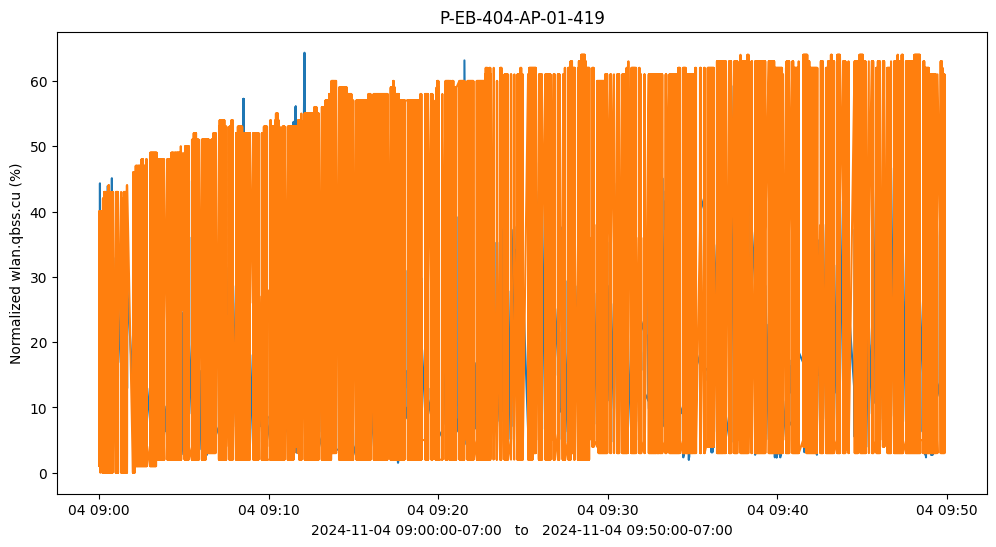

In [421]:
#Simple Plot, does not separate radios

# Further filter for the specific wlan.ta value 
# don't do this
#transmitter = 'your_desired_value'  # Replace with the wlan.ta value you're looking for
#filtered_df = filtered_df[filtered_df['wlan.ta'] == transmitter]

# Perform the calculation and plot
#(filtered_df["wlan.qbss.cu"] / 255).plot(x=filtered_df["aruba_erm.time"], marker=".")

# Generate evenly spaced time points
#num_points = len(filtered_df)  # Match the number of rows in the DataFrame
#evenly_spaced_times = pd.date_range(start=start_time, end=end_time, periods=num_points)

# Plot using the evenly spaced time as the x-axis
plt.figure(figsize=(12, 6))
plt.plot(filtered_df["aruba_erm.time"], (filtered_df["wlan.qbss.cu"] / 255) * 100)
plt.plot(filtered_df["aruba_erm.time"], (filtered_df["wlan.qbss.scount"]))
plt.xlabel(f"{start_time}   to   {end_time}")
plt.ylabel("Normalized wlan.qbss.cu (%)")
plt.title(f"{wlan_ap_name_value}")
plt.show()



In [37]:
#moved to plot_channel_stations function
#  Define the function to generate the plot
#inputs are dataframes filtered to the radio, and further filtered for each SSID
def plot_channel_stations(radio_df, eduroam_df, byu_wifi_df):
    
    plt.figure(figsize=(14, 7))  # Example size: 12 inches wide, 6 inches tall
    # Add a horizontal line at value 70 with 50% opacity
    plt.axhline(y=70, color='red', linestyle='-', alpha=0.2, zorder=-1)

    # Access the first record and get the value of 'radio_number'
    plot_radio_number = radio_df.iloc[0]["radio_number"]
    
    # Plot wlan.qbss.cu normalized as percentages
    plt.plot(radio_df["aruba_erm.time"], (radio_df["wlan.qbss.cu"] / 255) * 100, label="Channel Utilization (%)")

    # Fill the area below the line
    plt.fill_between(radio_df["aruba_erm.time"], (radio_df["wlan.qbss.cu"] / 255) * 100)


    # Plot total_scount
    plt.plot(radio_df["aruba_erm.time"], radio_df["total_scount"], label="Total Station Count")

    # Plot total_scount for "eduroam"
    #plt.plot(eduroam_df["aruba_erm.time"], eduroam_df["wlan.qbss.scount"], label="eduroam Station Count")

    # Plot total_scount for "BYU-WiFi"
    plt.plot(byu_wifi_df["aruba_erm.time"], byu_wifi_df["wlan.qbss.scount"], label="BYU-WiFi Station Count")

    
    
    # Plot total_adc
    plt.plot(radio_df["aruba_erm.time"], radio_df["wlan.qbss.adc"] / 32767 * 100, label="ADC (%)")

    #plot adc% + cu
    #adc updates less frequently than cu, but seems to be well correlated
    #plt.plot(radio_df["aruba_erm.time"], 100 - ((radio_df["wlan.qbss.adc"] / 32767 * 100) + (radio_df["wlan.qbss.cu"] / 255 * 100)), label="ADC + CU")



    # Add labels and title
    plt.xlabel(f"{start_time}   to   {end_time}", fontsize=14)
    plt.ylabel("Values", fontsize=14)
    plt.title(f"{wlan_ap_name_value} Radio {plot_radio_number}", fontsize=16)

    # Set the y-axis limits from 0 to 100
    plt.ylim(0, 100)

    # Add a legend
    plt.legend()

    # Display the plot
    plt.show()

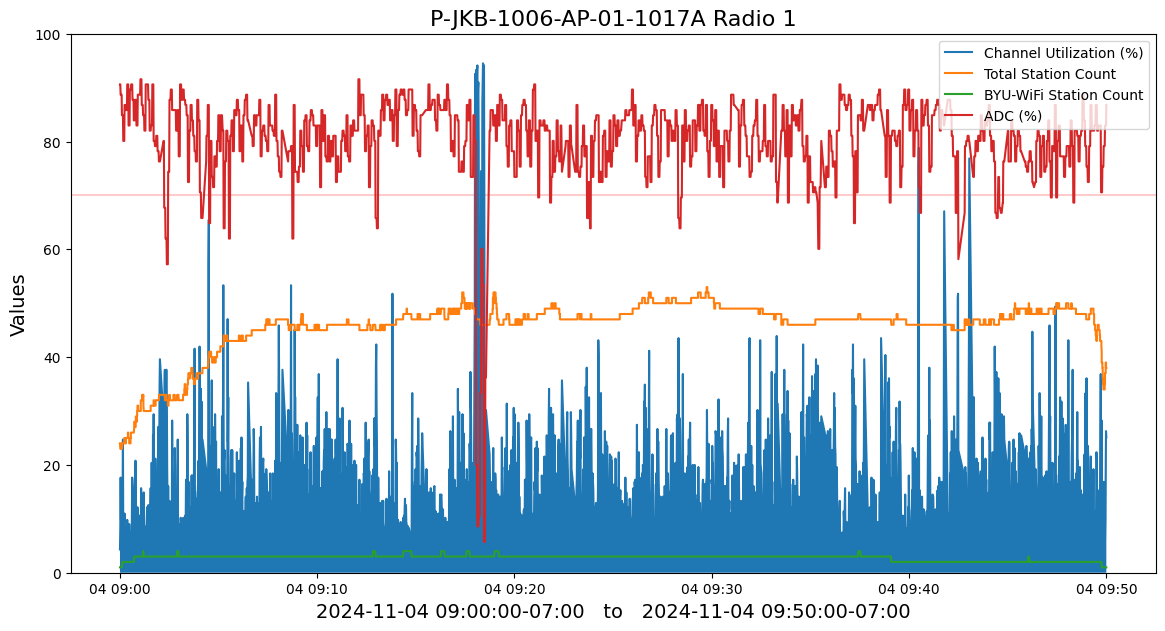

In [ ]:
#moved to graph function
# Filter the DataFrame for records where radio_number is 1
filtered_radio_1_df = filtered_df[filtered_df["radio_number"] == 1]
# Filter the data for "eduroam" and "BYU-WiFi" SSIDs
eduroam_radio_1_df = filtered_df[(filtered_df["wlan.ssid"] == "eduroam") & (filtered_df["radio_number"] == 1)]
byu_wifi_radio_1_df = filtered_df[(filtered_df["wlan.ssid"] == "BYU-WiFi") & (filtered_df["radio_number"] == 1)]

plot_channel_stations(filtered_radio_1_df, eduroam_radio_1_df, byu_wifi_radio_1_df)



In [39]:

#moved to graph function
#  Filter the DataFrame for records where radio_number is 2
filtered_radio_2_df = filtered_df[filtered_df["radio_number"] == 2]

# Check if any records exist for radio_number 2
if not filtered_radio_2_df.empty:
    # Filter the data for "eduroam" and "BYU-WiFi" SSIDs
    eduroam_radio_2_df = filtered_df[(filtered_df["wlan.ssid"] == "eduroam") & (filtered_df["radio_number"] == 2)]
    byu_wifi_radio_2_df = filtered_df[(filtered_df["wlan.ssid"] == "BYU-WiFi") & (filtered_df["radio_number"] == 2)]
    
    plot_channel_stations(filtered_radio_2_df, eduroam_radio_2_df, byu_wifi_radio_2_df)
else:
    print("No records found for radio 2.")



No records found for radio 2.


In [311]:
print(filtered_radio_2_df.head())

                    aruba_erm.time            wlan.ta wlan.vs.aruba.ap_name  \
0 2024-11-04 09:00:00.211710-07:00  d0:4d:c6:df:a7:e1    P-EB-404-AP-01-419   
1 2024-11-04 09:00:00.518694-07:00  d0:4d:c6:df:a7:e0    P-EB-404-AP-01-419   
4 2024-11-04 09:00:01.235687-07:00  d0:4d:c6:df:a7:e1    P-EB-404-AP-01-419   
5 2024-11-04 09:00:01.542557-07:00  d0:4d:c6:df:a7:e0    P-EB-404-AP-01-419   
8 2024-11-04 09:00:02.259648-07:00  d0:4d:c6:df:a7:e1    P-EB-404-AP-01-419   

  wlan.ssid  wlan.qbss.scount  wlan.qbss.cu  wlan.qbss.adc      wlan.ta_int  \
0   eduroam                40            13          27812  229032467605473   
1  BYU-WiFi                 2            13          27812  229032467605472   
4   eduroam                40            17          29687  229032467605473   
5  BYU-WiFi                 2            17          29687  229032467605472   
8   eduroam                40            23          29687  229032467605473   

   total_scount  radio_number  
0            42   

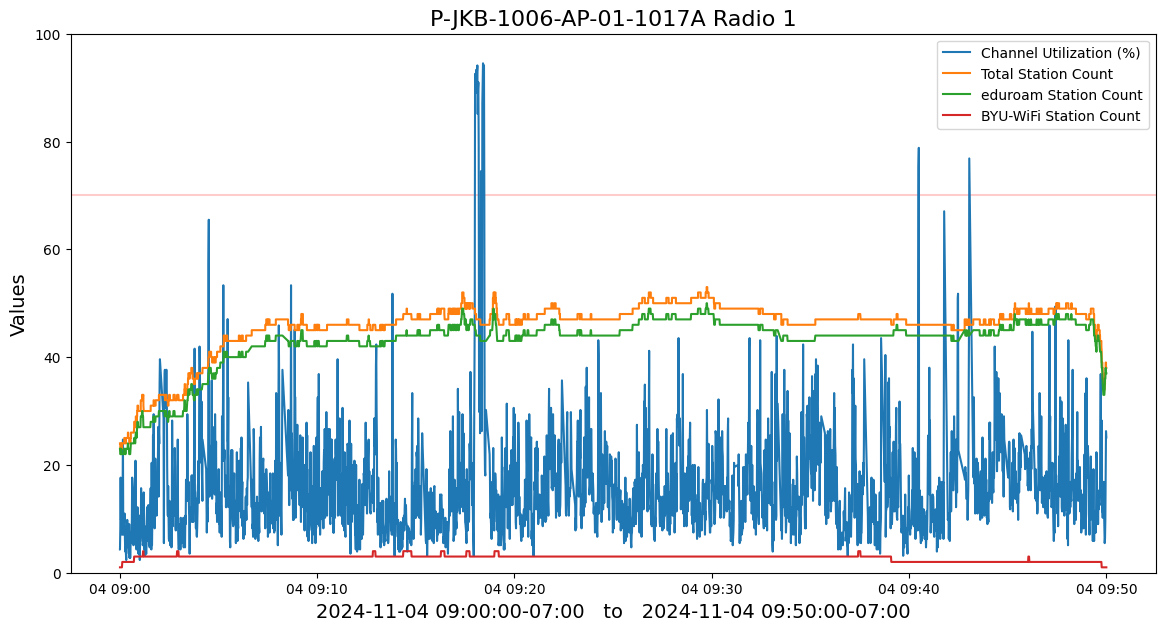

In [ ]:
# old, don't use
# Better plot for Radio 1

plt.figure(figsize=(14, 7))  # Example size: 12 inches wide, 6 inches tall

# Add a horizontal line at value 70 with 50% opacity
plt.axhline(y=70, color='red', linestyle='-', alpha=0.2)

# Filter the DataFrame for records where radio_number is 1
filtered_radio_1_df = filtered_df[filtered_df["radio_number"] == 1]
# Filter the data for "eduroam" and "BYU-WiFi" SSIDs
eduroam_radio_1_df = filtered_df[(filtered_df["wlan.ssid"] == "eduroam") & (filtered_df["radio_number"] == 1)]
byu_wifi_radio_1_df = filtered_df[(filtered_df["wlan.ssid"] == "BYU-WiFi") & (filtered_df["radio_number"] == 1)]

# Plot wlan.qbss.cu normalized as percentages
plt.plot(filtered_radio_1_df["aruba_erm.time"], (filtered_radio_1_df["wlan.qbss.cu"] / 255) * 100, label="Channel Utilization (%)")

# Plot total_scount
plt.plot(filtered_radio_1_df["aruba_erm.time"], filtered_radio_1_df["total_scount"], label="Total Station Count")

# Plot total_scount for "eduroam"
plt.plot(eduroam_radio_1_df["aruba_erm.time"], eduroam_radio_1_df["wlan.qbss.scount"], label="eduroam Station Count")

# Plot total_scount for "BYU-WiFi"
plt.plot(byu_wifi_radio_1_df["aruba_erm.time"], byu_wifi_radio_1_df["wlan.qbss.scount"], label="BYU-WiFi Station Count")


# Add labels and title
plt.xlabel(f"{start_time}   to   {end_time}", fontsize=14)
plt.ylabel("Values", fontsize=14)
plt.title(f"{wlan_ap_name_value} Radio 1", fontsize=16)

# Set the y-axis limits from 0 to 100
plt.ylim(0, 100)

# Add a legend
plt.legend()

# Display the plot
plt.show()

In [312]:
#old, don't use
#analysis - this needs to be broken down by radio
# Count the total number of data points
total_data_points = len(filtered_df)

# Calculate the greatest value of wlan.qbss.cu
greatest_cutil = ((filtered_df["wlan.qbss.cu"].max() / 255) * 100)

# Calculate the least value of wlan.qbss.cu
least_cutil = ((filtered_df["wlan.qbss.cu"].min() / 255) * 100)

# Count the number of data points where wlan.qbss.cu is greater than 178
greater_than_178_count = (filtered_df["wlan.qbss.cu"] > 178).sum()

# Calculate the percentage of data points where wlan.qbss.cu is greater than 178
percentage_greater_than_178 = (greater_than_178_count / total_data_points) * 100

# Median wlan.qbss.cu
median_cutil = ((filtered_df["wlan.qbss.cu"].median() / 255) * 100)

# Calculate the greatest value of wlan.qbss.scount
greatest_scount = filtered_df["total_scount"].max()

# Calculate the median value of wlan.qbss.scount
median_scount = filtered_df["total_scount"].median()

# Calculate the least value of wlan.qbss.scount
least_scount = filtered_df["total_scount"].min()

# Print the results
print(f"Total beacons: {total_data_points}")
print(f"Number of beacons with high channel utilization: {greater_than_178_count}")
print(f"Percentage of beacons with high channel utilization: {percentage_greater_than_178:.2f}%")
print(f"Highest channel utilization: {greatest_cutil:.2f}%")
print(f"Median channel utilization: {median_cutil:.2f}%")
print(f"Lowest channel utilization: {least_cutil:.2f}%")
print(f"Highest station count: {greatest_scount:.0f}")
print(f"Median station count: {median_scount:.0f}")
print(f"Lowest station count: {least_scount:.0f}")

Total beacons: 7841
Number of beacons with high channel utilization: 0
Percentage of beacons with high channel utilization: 0.00%
Highest channel utilization: 64.31%
Median channel utilization: 11.37%
Lowest channel utilization: 1.57%
Highest station count: 68
Median station count: 44
Lowest station count: 1


In [313]:
# simple calculation that does not account for busy time prior to first beacon
# use below for better estimation
# Ensure timestamp is sorted
filtered_df = filtered_df.sort_values(by="aruba_erm.time")

# Create a boolean mask for wlan.qbss.cu > 178
condition = filtered_df["wlan.qbss.cu"] > 178

# Assign group numbers for consecutive periods where condition is True
filtered_df["group"] = (condition != condition.shift()).cumsum() * condition

# Filter only groups where condition is True
valid_groups = filtered_df[filtered_df["group"] > 0]

# Calculate the duration for each group
group_durations = valid_groups.groupby("group")["aruba_erm.time"].agg(["min", "max"])
group_durations["duration"] = (group_durations["max"] - group_durations["min"]).dt.total_seconds()

# Find the longest duration
longest_duration_row = group_durations.loc[group_durations["duration"].idxmax()]
longest_duration = longest_duration_row["duration"]
longest_start_time = longest_duration_row["min"]
longest_end_time = longest_duration_row["max"]

# Print the result
print(f"Longest consecutive duration where wlan.qbss.cu > 178: {longest_duration} seconds")
print(f"Start time: {longest_start_time}")
print(f"End time: {longest_end_time}")
#may actually be longer depending on the time before the first beacon and after the last one

ValueError: attempt to get argmax of an empty sequence

In [ ]:
# do not use, see below
# # assumes beacon information represents the time since the last beacon was received. this is an estimation, but better than skipping missed beacons
# need to add error handling where no beacons are busier than 178
# remove group column or name it better
# filter by radio

# Ensure the DataFrame is sorted by timestamp
filtered_df = filtered_df.sort_values(by="aruba_erm.time").reset_index(drop=True)

# Create a boolean mask for wlan.qbss.cu > 178
condition = filtered_df["wlan.qbss.cu"] > 178

# Assign group numbers for consecutive periods where condition is True
filtered_df["group"] = (condition != condition.shift()).cumsum() * condition

# Filter groups where wlan.qbss.cu > 178
valid_groups = filtered_df[filtered_df["group"] > 0]

# Find the start and end of each group
group_details = valid_groups.groupby("group").agg(
    first_index=("aruba_erm.time", "idxmin"),
    last_index=("aruba_erm.time", "idxmax")
)

# Add the prior timestamp and the first timestamp of the sequence
group_details["prior_start_time"] = group_details["first_index"] - 1
group_details["prior_start_time"] = group_details["prior_start_time"].apply(
    lambda idx: filtered_df.loc[idx, "aruba_erm.time"] if idx >= 0 else None
)
group_details["first_in_sequence_time"] = valid_groups.groupby("group")["aruba_erm.time"].min()

# Calculate duration for each group
group_details["start_time"] = group_details["prior_start_time"]
group_details["end_time"] = valid_groups.groupby("group")["aruba_erm.time"].max()
group_details["duration"] = (group_details["end_time"] - group_details["start_time"]).dt.total_seconds()

# Find the group with the longest duration
longest_group = group_details["duration"].idxmax()
longest_row = group_details.loc[longest_group]

# Extract details of the longest duration
longest_duration = longest_row["duration"]
longest_prior_start_time = longest_row["start_time"]
longest_first_in_sequence_time = longest_row["first_in_sequence_time"]
longest_end_time = longest_row["end_time"]

# Print results
print(f"Longest consecutive duration of high channel use: {longest_duration} seconds")
print(f"Previous beacon time: {longest_prior_start_time}")
print(f"First beacon time: {longest_first_in_sequence_time}")
print(f"Last beacon time: {longest_end_time}")


TypeError: Addition/subtraction of integers and integer-arrays with DatetimeArray is no longer supported.  Instead of adding/subtracting `n`, use `n * obj.freq`

In [319]:
# do not use, see below
# Ensure the DataFrame is sorted by timestamp
filtered_df = filtered_df.sort_values(by="aruba_erm.time").reset_index(drop=True)

# Create a boolean mask for wlan.qbss.cu > 178
condition = filtered_df["wlan.qbss.cu"] > 178

# Assign group numbers for consecutive periods where condition is True
filtered_df["group"] = (condition != condition.shift()).cumsum() * condition

# Filter groups where wlan.qbss.cu > 178
valid_groups = filtered_df[filtered_df["group"] > 0]

# Check if there are valid groups (i.e., groups where wlan.qbss.cu > 178)
if valid_groups.empty:
    print("No records found where channel utilization is > 70%.")
else:
    # Find the start and end of each group
    group_details = valid_groups.groupby("group").agg(
        first_index=("aruba_erm.time", "idxmin"),
        last_index=("aruba_erm.time", "idxmax")
    )

    # Add the prior timestamp and the first timestamp of the sequence
    group_details["prior_start_time"] = group_details["first_index"] - 1
    group_details["prior_start_time"] = group_details["prior_start_time"].apply(
        lambda idx: filtered_df.loc[idx, "aruba_erm.time"] if idx >= 0 else None
    )
    group_details["first_in_sequence_time"] = valid_groups.groupby("group")["aruba_erm.time"].min()

    # Calculate duration for each group
    group_details["start_time"] = group_details["prior_start_time"]
    group_details["end_time"] = valid_groups.groupby("group")["aruba_erm.time"].max()
    group_details["duration"] = (group_details["end_time"] - group_details["start_time"]).dt.total_seconds()

    # Find the group with the longest duration
    longest_group = group_details["duration"].idxmax()
    longest_row = group_details.loc[longest_group]

    # Extract details of the longest duration
    longest_duration = longest_row["duration"]
    longest_prior_start_time = longest_row["start_time"]
    longest_first_in_sequence_time = longest_row["first_in_sequence_time"]
    longest_end_time = longest_row["end_time"]

    # Print results
    print(f"Longest consecutive duration of high channel use: {longest_duration} seconds")
    print(f"Previous beacon time: {longest_prior_start_time}")
    print(f"First beacon time: {longest_first_in_sequence_time}")
    print(f"Last beacon time: {longest_end_time}")


No records found where channel utilization is > 70%.


In [40]:
#moved to analyze_radio_group function, graph function
# Function to perform the analysis for a given radio DataFrame
def analyze_radio_group(radio_df, radio_number):
    # Ensure the DataFrame is sorted by timestamp
    radio_df = radio_df.sort_values(by="aruba_erm.time").reset_index(drop=True)



    # Count the total number of data points
    total_data_points = len(radio_df)

    # Calculate the greatest value of wlan.qbss.cu
    greatest_cutil = ((radio_df["wlan.qbss.cu"].max() / 255) * 100)

    # Calculate the least value of wlan.qbss.cu
    least_cutil = ((radio_df["wlan.qbss.cu"].min() / 255) * 100)

    # Count the number of data points where wlan.qbss.cu is greater than 178
    greater_than_178_count = (radio_df["wlan.qbss.cu"] > 178).sum()

    # Calculate the percentage of data points where wlan.qbss.cu is greater than 178
    percentage_greater_than_178 = (greater_than_178_count / total_data_points) * 100

    # Median wlan.qbss.cu
    median_cutil = ((radio_df["wlan.qbss.cu"].median() / 255) * 100)

    # Calculate the greatest value of wlan.qbss.scount
    greatest_scount = radio_df["total_scount"].max()

    # Calculate the median value of wlan.qbss.scount
    median_scount = radio_df["total_scount"].median()

    # Calculate the least value of wlan.qbss.scount
    least_scount = radio_df["total_scount"].min()

    # Print the results
    print(f"--- Radio Number {radio_number} ---")
    print(f"Total beacons: {total_data_points}")
    print(f"Number of beacons with high channel utilization: {greater_than_178_count}")
    print(f"Percentage of beacons with high channel utilization: {percentage_greater_than_178:.2f}%")
    print(f"Highest channel utilization: {greatest_cutil:.2f}%")
    print(f"Median channel utilization: {median_cutil:.2f}%")
    print(f"Lowest channel utilization: {least_cutil:.2f}%")
    print(f"Highest station count: {greatest_scount:.0f}")
    print(f"Median station count: {median_scount:.0f}")
    print(f"Lowest station count: {least_scount:.0f}")





    # Create a boolean mask for wlan.qbss.cu > 178
    condition = radio_df["wlan.qbss.cu"] > 178

    # Assign group numbers for consecutive periods where condition is True
    radio_df["group"] = (condition != condition.shift()).cumsum() * condition

    # Filter groups where wlan.qbss.cu > 178
    valid_groups = radio_df[radio_df["group"] > 0]

    # Check if there are valid groups (i.e., groups where wlan.qbss.cu > 178)
    if valid_groups.empty:
        print(f"No records found where wlan.qbss.cu > 178 for radio_number {radio_number}.")
    else:
        # Find the start and end of each group
        group_details = valid_groups.groupby("group").agg(
            first_index=("aruba_erm.time", "idxmin"),
            last_index=("aruba_erm.time", "idxmax")
        )

        # Add the prior timestamp and the first timestamp of the sequence
        group_details["prior_start_time"] = group_details["first_index"] - 1
        group_details["prior_start_time"] = group_details["prior_start_time"].apply(
            lambda idx: radio_df.loc[idx, "aruba_erm.time"] if idx >= 0 else None
        )
        group_details["first_in_sequence_time"] = valid_groups.groupby("group")["aruba_erm.time"].min()

        # Calculate duration for each group
        group_details["start_time"] = group_details["prior_start_time"]
        group_details["end_time"] = valid_groups.groupby("group")["aruba_erm.time"].max()
        group_details["duration"] = (group_details["end_time"] - group_details["start_time"]).dt.total_seconds()

        # Find the group with the longest duration
        longest_group = group_details["duration"].idxmax()
        longest_row = group_details.loc[longest_group]

        # Extract details of the longest duration
        longest_duration = longest_row["duration"]
        longest_prior_start_time = longest_row["start_time"]
        longest_first_in_sequence_time = longest_row["first_in_sequence_time"]
        longest_end_time = longest_row["end_time"]

        # Print results for the specific radio_number
        print(f"Longest consecutive duration of high channel use: {longest_duration} seconds")
        print(f"Previous beacon time: {longest_prior_start_time}")
        print(f"First beacon time: {longest_first_in_sequence_time}")
        print(f"Last beacon time: {longest_end_time}")
        print("\n")

# Run the analysis for radio_number 1 (using filtered_radio_1_df)
if not filtered_radio_1_df.empty:
    analyze_radio_group(filtered_radio_1_df, 1)

# Run the analysis for radio_number 2 (using filtered_radio_2_df) only if it's not empty
if not filtered_radio_2_df.empty:
    analyze_radio_group(filtered_radio_2_df, 2)


--- Radio Number 1 ---
Total beacons: 5508
Number of beacons with high channel utilization: 48
Percentage of beacons with high channel utilization: 0.87%
Highest channel utilization: 94.51%
Median channel utilization: 13.73%
Lowest channel utilization: 2.35%
Highest station count: 53
Median station count: 47
Lowest station count: 23
Longest consecutive duration of high channel use: 12.076264 seconds
Previous beacon time: 2024-11-04 09:17:59.089071-07:00
First beacon time: 2024-11-04 09:18:00.097867-07:00
Last beacon time: 2024-11-04 09:18:11.165335-07:00




In [315]:
print(filtered_df[filtered_df["group"] != 0])

Empty DataFrame
Columns: [aruba_erm.time, wlan.ta, wlan.vs.aruba.ap_name, wlan.ssid, wlan.qbss.scount, wlan.qbss.cu, wlan.qbss.adc, wlan.ta_int, total_scount, radio_number, group]
Index: []


In [316]:
print(group_details.head())

Empty DataFrame
Columns: [first_index, last_index, prior_start_time, first_in_sequence_time, start_time, end_time]
Index: []


In [317]:
# Check all variables in the global scope and filter DataFrames
dataframes = {name: obj for name, obj in globals().items() if isinstance(obj, pd.DataFrame)}

# Print the names of the DataFrames
print("DataFrames in memory:", list(dataframes.keys()))

# Print the head of each DataFrame
for name, df in dataframes.items():
    print(f"DataFrame: {name}")
    print(df.head(), "\n")  # Print the first 5 rows


DataFrames in memory: ['df', 'filtered_df', 'valid_groups', 'group_durations', 'group_details', 'bssid_info', 'eduroam_df', 'byu_wifi_df', 'filtered_radio_1', 'eduroam_radio_1', 'byu_wifi_radio_1', 'filtered_radio_1_df', 'eduroam_radio_1_df', 'byu_wifi_radio_1_df', 'filtered_radio_2_df', 'eduroam_radio_2_df', 'byu_wifi_radio_2_df']
DataFrame: df
                                      wlan.ta wlan.vs.aruba.ap_name wlan.ssid  \
aruba_erm.time                                                                  
2024-11-03 01:00:00.140574  d0:4d:c6:df:a7:d1    P-EB-404-AP-01-419   eduroam   
2024-11-03 01:00:00.550216  d0:4d:c6:df:a7:e1    P-EB-404-AP-01-419   eduroam   
2024-11-03 01:00:00.959816  d0:4d:c6:df:a7:e0    P-EB-404-AP-01-419  BYU-WiFi   
2024-11-03 01:00:01.062176  d0:4d:c6:df:a7:d0    P-EB-404-AP-01-419  BYU-WiFi   
2024-11-03 01:00:01.164615  d0:4d:c6:df:a7:d1    P-EB-404-AP-01-419   eduroam   

                            wlan.qbss.scount  wlan.qbss.cu  wlan.qbss.adc  
aruba_er

In [189]:
print(filtered_df.columns)

Index(['aruba_erm.time', 'wlan.ta', 'wlan.vs.aruba.ap_name', 'wlan.ssid',
       'wlan.qbss.scount', 'wlan.qbss.cu', 'wlan.qbss.adc', 'wlan.ta_int',
       'total_scount', 'group'],
      dtype='object')


In [244]:
print(filtered_df.dtypes)

aruba_erm.time           datetime64[us, Etc/GMT+7]
wlan.ta                             string[python]
wlan.vs.aruba.ap_name               string[python]
wlan.ssid                           string[python]
wlan.qbss.scount                             int64
wlan.qbss.cu                                 int64
wlan.qbss.adc                                int64
wlan.ta_int                                  int64
total_scount                                 int64
group                                        int64
dtype: object


In [56]:
print(filtered_df.head(50))

                     aruba_erm.time            wlan.ta  \
0  2024-11-04 09:00:00.320384-07:00  b0:1f:8c:c0:bc:70   
1  2024-11-04 09:00:00.320513-07:00  b0:1f:8c:c0:bc:71   
2  2024-11-04 09:00:01.323224-07:00  b0:1f:8c:c0:bc:70   
3  2024-11-04 09:00:01.323353-07:00  b0:1f:8c:c0:bc:71   
4  2024-11-04 09:00:02.326393-07:00  b0:1f:8c:c0:bc:70   
5  2024-11-04 09:00:02.326522-07:00  b0:1f:8c:c0:bc:71   
6  2024-11-04 09:00:03.330413-07:00  b0:1f:8c:c0:bc:70   
7  2024-11-04 09:00:03.330544-07:00  b0:1f:8c:c0:bc:71   
8  2024-11-04 09:00:04.335231-07:00  b0:1f:8c:c0:bc:70   
9  2024-11-04 09:00:04.335366-07:00  b0:1f:8c:c0:bc:71   
10 2024-11-04 09:00:05.340527-07:00  b0:1f:8c:c0:bc:70   
11 2024-11-04 09:00:05.340664-07:00  b0:1f:8c:c0:bc:71   
12 2024-11-04 09:00:06.345193-07:00  b0:1f:8c:c0:bc:70   
13 2024-11-04 09:00:06.345329-07:00  b0:1f:8c:c0:bc:71   
14 2024-11-04 09:00:07.349684-07:00  b0:1f:8c:c0:bc:70   
15 2024-11-04 09:00:07.349813-07:00  b0:1f:8c:c0:bc:71   
16 2024-11-04 